# Conventional Neural Network vs Physics-Augmented Neural Network (PANN)

This notebook uses the **same Gent material constants, synthetic-data generation, noise model, 50,000 observations, learning rate, hidden-unit count, and 10,000 epochs** 
**Controlled comparison:** both networks fit the same noisy stress observations with the same inverse-noise-variance weighted MSE. The PANN uses your original softplus energy expression without stochastic hard-concrete gates; the conventional NN predicts stress directly. Removing gates and the sparsity penalty is deliberate: this isolates architecture/physics effects rather than comparing different regularizers. The conventional network has one hidden layer of 32 units; parameter counts are reported rather than assumed equal.

The held-out validation subset is selected from the original 50,000 samples; **no new training data are generated**. Separate clean Gent curves are used only for evaluation.

In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import time
import copy

# Same hyperparameters as original notebook
mu = 0.8
jm = 40.0
Identity = torch.eye(3)
num_samples = 50000
lamda_min, lamda_max = 1.0, 4.0
eta_min, eta_max = 0.005, 0.03
m = 32
learning_rate = 0.01
num_epochs = 10000

torch.manual_seed(42)  # Reproducible comparison


In [13]:
# Original Gent stress and noise generation (unchanged equations)
def gent_stress_function(lamda, mu, jm):
    I1 = lamda**2 + 2/lamda
    stress = mu * (lamda - 1/lamda**2) / (1 - (I1 - 3)/jm)
    return stress

def deformation_gradient(lamda):
    diagonal_values = torch.stack([
        lamda,
        lamda**(-0.5),
        lamda**(-0.5)
    ], dim=-1)
    return torch.diag_embed(diagonal_values)

def frobenius_norm(F):
    return torch.sqrt(torch.sum((F - Identity)**2, dim=(-2, -1)))

def add_noise(P_true_train, eta_min, eta_max, lamda):
    P_char = torch.max(torch.abs(P_true_train))
    noise_sd_min = eta_min * P_char
    noise_sd_max = eta_max * P_char
    F = deformation_gradient(lamda)
    F_lambdamax = deformation_gradient(torch.max(lamda))
    q = 2.0
    t = frobenius_norm(F)
    ksy = torch.randn_like(P_true_train)
    conditional_noise_variance = torch.square(noise_sd_min) + (torch.square(noise_sd_max) - torch.square(noise_sd_min)) * ((t / frobenius_norm(F_lambdamax))**q)
    noise = torch.sqrt(conditional_noise_variance) * ksy
    return noise, conditional_noise_variance

def generate_synthetic_data(num_samples, lamda_min, lamda_max, eta_min, eta_max):
    lamda_train = torch.linspace(lamda_min, lamda_max, num_samples)
    I1_train = lamda_train**2 + 2/lamda_train
    P_true_train = gent_stress_function(lamda_train, mu, jm)
    noise, conditional_noise_variance = add_noise(P_true_train, eta_min, eta_max, lamda_train)
    Y_train = P_true_train + noise
    Y_train = Y_train.reshape(-1, 1)
    lamda_train = lamda_train.reshape(-1, 1)
    I1_train = I1_train.reshape(-1, 1)
    x = torch.cat((lamda_train, I1_train, Y_train), dim=1)
    return x, conditional_noise_variance

x, conditional_noise_variance = generate_synthetic_data(
    num_samples=50000, lamda_min=1.0, lamda_max=4.0,
    eta_min=0.005, eta_max=0.03
)


## Training and validation split

An 80/20 split is introduced only to measure validation error. It partitions the **existing 50,000 observations**; it does not change their values. The random split and its seed are fixed for both networks.

In [14]:
indices = torch.randperm(len(x))
n_train = int(0.8 * len(x))
train_idx = indices[:n_train]
val_idx = indices[n_train:]

x_train = x[train_idx]
x_val = x[val_idx]
variance_train = conditional_noise_variance[train_idx].reshape(-1, 1)
variance_val = conditional_noise_variance[val_idx].reshape(-1, 1)

print('Training samples:', len(x_train))
print('Validation samples:', len(x_val))


Training samples: 40000
Validation samples: 10000


In [15]:
# Conventional neural network: stretch -> stress
class ConventionalNN(nn.Module):
    def __init__(self, m=32):
        super().__init__()
        self.fc1 = nn.Linear(1, m)
        self.fc2 = nn.Linear(m, 1)

    def forward(self, lamda):
        return self.fc2(F.softplus(self.fc1(lamda)))


# PANN: original softplus energy equation, without random sparsification gates
class PANN(nn.Module):
    def __init__(self, m=32):
        super().__init__()
        self.a = nn.Parameter(torch.randn(1))
        self.c = nn.Parameter(torch.randn(m))
        self.w = nn.Parameter(torch.randn(m))
        self.b = nn.Parameter(torch.randn(m))

    def forward(self, I1):
        a = F.softplus(self.a)
        c = F.softplus(self.c)
        w = F.softplus(self.w)
        b = self.b
        z = (I1 - 3) * w + b
        hidden = F.softplus(z) - F.softplus(b)
        psi = a * (I1 - 3) + torch.sum(c * hidden, dim=-1, keepdim=True)
        return psi


def pann_stress(model, lamda):
    I1 = (lamda**2 + 2 / lamda).detach().requires_grad_(True)
    psi = model(I1)
    dpsi_dI1 = torch.autograd.grad(
        psi, I1, grad_outputs=torch.ones_like(psi), create_graph=True
    )[0]
    return 2 * dpsi_dI1 * (lamda - 1 / lamda**2)


def predict_stress(model, lamda, is_pann):
    if is_pann:
        return pann_stress(model, lamda)
    return model(lamda)


In [16]:
# Same weighted stress loss for both models
# The original noise variance is preserved; no sparsity penalty is applied.
def weighted_loss(model, data, noise_variance, is_pann):
    lamda = data[:, 0:1]
    Y = data[:, 2:3]
    P_pred = predict_stress(model, lamda, is_pann)
    return torch.mean((P_pred - Y)**2 / noise_variance)


def rmse_on_data(model, data, is_pann):
    # Unweighted RMSE, easier to interpret than weighted training loss
    P_pred = predict_stress(model, data[:, 0:1], is_pann)
    return torch.sqrt(torch.mean((P_pred - data[:, 2:3])**2)).item()


pann = PANN(m=32)
conventional_nn = ConventionalNN(m=32)

print('PANN parameters:', sum(p.numel() for p in pann.parameters()))
print('Conventional NN parameters:', sum(p.numel() for p in conventional_nn.parameters()))


PANN parameters: 97
Conventional NN parameters: 97


## Train both models

Both use Adam with `lr=0.01` and `num_epochs=10000`, as in the uploaded notebook. Full-batch training on 50,000 points for 10,000 epochs can take a long time, especially for the PANN. Validation is measured every 100 epochs to keep the notebook simple and reduce overhead.

We record **validation RMSE**, **weighted training loss**, and **elapsed training time**. Validation does not update model parameters. The PANN requires autograd even during evaluation because stress is the derivative of its energy.

In [17]:
def train_model(model, is_pann):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    epochs, train_losses, val_rmses, times = [], [], [], []
    start = time.perf_counter()

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        loss = weighted_loss(model, x_train, variance_train, is_pann)
        loss.backward()
        optimizer.step()

        if epoch % 100 == 0 or epoch == num_epochs - 1:
            # Validation requires energy derivatives, but no backward/update
            val_rmse = rmse_on_data(model, x_val, is_pann)
            elapsed = time.perf_counter() - start
            epochs.append(epoch + 1)
            train_losses.append(loss.item())
            val_rmses.append(val_rmse)
            times.append(elapsed)
            if epoch % 1000 == 0 or epoch == num_epochs - 1:
                print(f'Epoch {epoch+1}/{num_epochs} | Loss {loss.item():.6f} | Validation RMSE {val_rmse:.6f}')

    return epochs, train_losses, val_rmses, times


print('Training conventional NN')
nn_epochs, nn_loss, nn_val, nn_time = train_model(conventional_nn, False)

print('Training PANN')
pann_epochs, pann_loss, pann_val, pann_time = train_model(pann, True)


Training conventional NN
Epoch 1/10000 | Loss 329.121033 | Validation RMSE 1.497812
Epoch 1001/10000 | Loss 2.812803 | Validation RMSE 0.145453
Epoch 2001/10000 | Loss 1.397808 | Validation RMSE 0.113371
Epoch 3001/10000 | Loss 1.140731 | Validation RMSE 0.095835
Epoch 4001/10000 | Loss 1.091232 | Validation RMSE 0.092371
Epoch 5001/10000 | Loss 1.072169 | Validation RMSE 0.090681
Epoch 6001/10000 | Loss 1.064081 | Validation RMSE 0.089841
Epoch 7001/10000 | Loss 1.059601 | Validation RMSE 0.089383
Epoch 8001/10000 | Loss 1.056360 | Validation RMSE 0.089105
Epoch 9001/10000 | Loss 1.053629 | Validation RMSE 0.088918
Epoch 10000/10000 | Loss 1.051159 | Validation RMSE 0.088777
Training PANN
Epoch 1/10000 | Loss 668854.250000 | Validation RMSE 75.501411
Epoch 1001/10000 | Loss 631.616699 | Validation RMSE 3.069641
Epoch 2001/10000 | Loss 116.705704 | Validation RMSE 1.142592
Epoch 3001/10000 | Loss 65.731537 | Validation RMSE 0.719787
Epoch 4001/10000 | Loss 35.766426 | Validation RMSE 0

## Plot 1 — Training loss and validation RMSE

Weighted training loss is **not the same unit** as validation RMSE. They are therefore shown in separate figures.

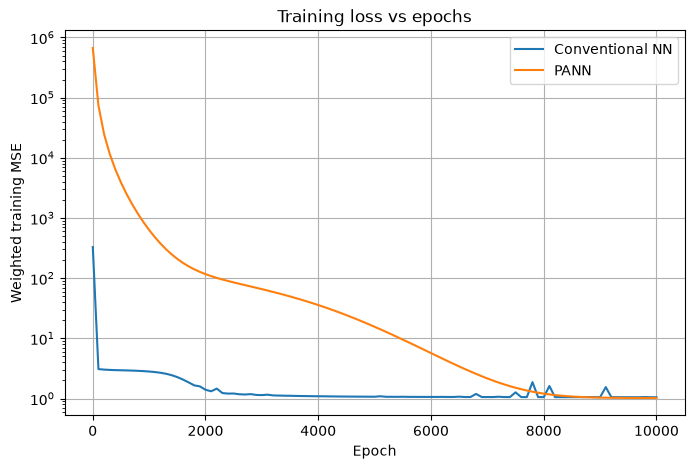

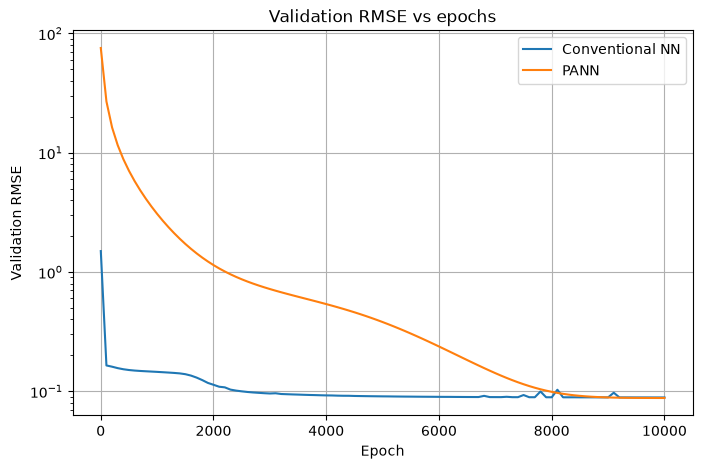

In [18]:
plt.figure(figsize=(8, 5))
plt.semilogy(nn_epochs, nn_loss, label='Conventional NN')
plt.semilogy(pann_epochs, pann_loss, label='PANN')
plt.xlabel('Epoch')
plt.ylabel('Weighted training MSE')
plt.title('Training loss vs epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.semilogy(nn_epochs, nn_val, label='Conventional NN')
plt.semilogy(pann_epochs, pann_val, label='PANN')
plt.xlabel('Epoch')
plt.ylabel('Validation RMSE')
plt.title('Validation RMSE vs epochs')
plt.legend()
plt.grid(True)
plt.show()


## Plot 2 — Validation RMSE vs training time

This is more informative than epochs alone because the PANN differentiates its energy with respect to the invariant.

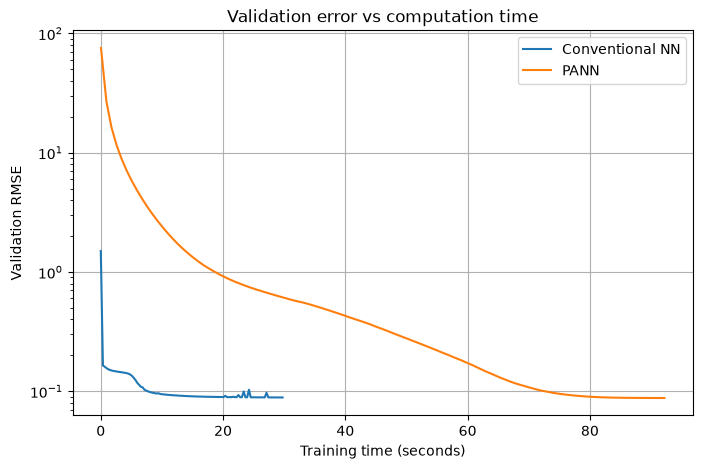

In [19]:
plt.figure(figsize=(8, 5))
plt.semilogy(nn_time, nn_val, label='Conventional NN')
plt.semilogy(pann_time, pann_val, label='PANN')
plt.xlabel('Training time (seconds)')
plt.ylabel('Validation RMSE')
plt.title('Validation error vs computation time')
plt.legend()
plt.grid(True)
plt.show()


## Plot 3 — Stress–stretch interpolation and extrapolation

The models train only on observations with stretch in `[1, 4]`. Values in `(4, 5]` are **evaluation-only** and compared with the clean analytical Gent stress. The Gent curve is defined over this full interval for the original `J_m=40`.

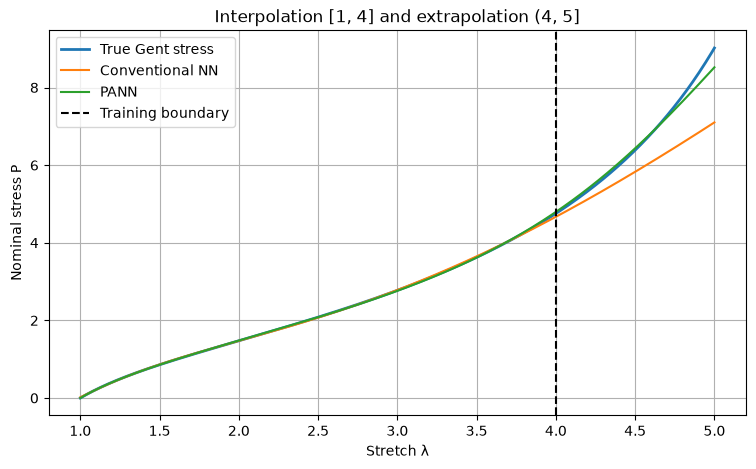

In [20]:
lamda_plot = torch.linspace(1.0, 5.0, 500).reshape(-1, 1)
P_true = gent_stress_function(lamda_plot, mu, jm).detach()
P_nn = predict_stress(conventional_nn, lamda_plot, False).detach()
P_pann = predict_stress(pann, lamda_plot, True).detach()

plt.figure(figsize=(9, 5))
plt.plot(lamda_plot, P_true, label='True Gent stress', linewidth=2)
plt.plot(lamda_plot, P_nn, label='Conventional NN')
plt.plot(lamda_plot, P_pann, label='PANN')
plt.axvline(4.0, color='black', linestyle='--', label='Training boundary')
plt.xlabel('Stretch λ')
plt.ylabel('Nominal stress P')
plt.title('Interpolation [1, 4] and extrapolation (4, 5]')
plt.legend()
plt.grid(True)
plt.show()


## Plot 4 — Absolute stress error

Separates errors in the training range and outside it. The comparison is against **clean Gent stress**, not noisy training observations.

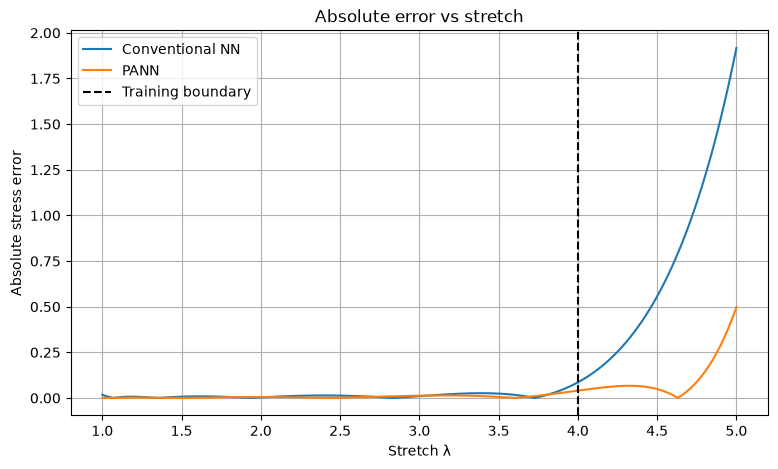

In [21]:
plt.figure(figsize=(9, 5))
plt.plot(lamda_plot, torch.abs(P_nn - P_true), label='Conventional NN')
plt.plot(lamda_plot, torch.abs(P_pann - P_true), label='PANN')
plt.axvline(4.0, color='black', linestyle='--', label='Training boundary')
plt.xlabel('Stretch λ')
plt.ylabel('Absolute stress error')
plt.title('Absolute error vs stretch')
plt.legend()
plt.grid(True)
plt.show()


## Plot 5 — Physical consistency and numerical results

For the PANN, reference stress is zero by construction, and the energy is normalized at `I1=3`. The conventional NN has no such constraints. We report `P(1)` and the number of negative slopes on the plotted tensile interval. These are **diagnostics**, not proof of full 3D constitutive stability.


Conventional NN
Interpolation RMSE: 0.018022
Extrapolation RMSE: 0.877444
Stress at λ=1: 0.017656
Negative stress increments: 0

PANN
Interpolation RMSE: 0.010258
Extrapolation RMSE: 0.15389
Stress at λ=1: 0.0
Negative stress increments: 0


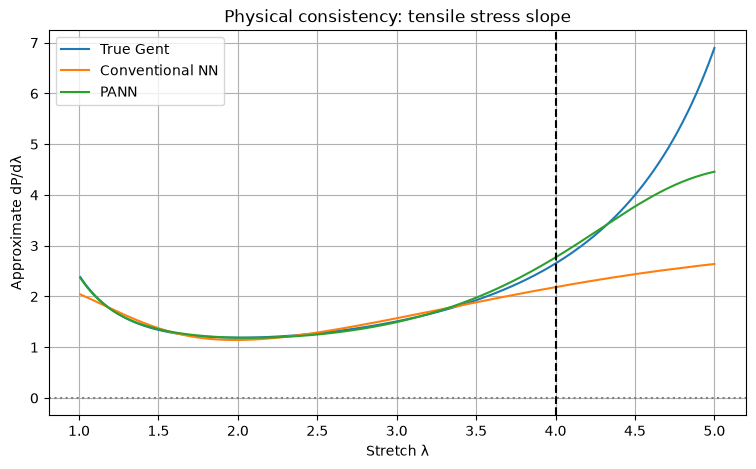

Final elapsed training time (s):
Conventional NN: 29.74
PANN: 92.19


In [22]:
def rmse(pred, true):
    return torch.sqrt(torch.mean((pred - true)**2)).item()

inside = lamda_plot[:, 0] <= 4.0
outside = lamda_plot[:, 0] > 4.0

for name, pred in [('Conventional NN', P_nn), ('PANN', P_pann)]:
    print(f'\n{name}')
    print('Interpolation RMSE:', round(rmse(pred[inside], P_true[inside]), 6))
    print('Extrapolation RMSE:', round(rmse(pred[outside], P_true[outside]), 6))
    print('Stress at λ=1:', round(pred[0].item(), 6))
    print('Negative stress increments:', int((pred[1:] - pred[:-1] < 0).sum().item()))

plt.figure(figsize=(9, 5))
plt.plot(lamda_plot[1:], torch.diff(P_true[:, 0]) / torch.diff(lamda_plot[:, 0]), label='True Gent')
plt.plot(lamda_plot[1:], torch.diff(P_nn[:, 0]) / torch.diff(lamda_plot[:, 0]), label='Conventional NN')
plt.plot(lamda_plot[1:], torch.diff(P_pann[:, 0]) / torch.diff(lamda_plot[:, 0]), label='PANN')
plt.axhline(0, color='gray', linestyle=':')
plt.axvline(4.0, color='black', linestyle='--')
plt.xlabel('Stretch λ')
plt.ylabel('Approximate dP/dλ')
plt.title('Physical consistency: tensile stress slope')
plt.legend()
plt.grid(True)
plt.show()

print('Final elapsed training time (s):')
print('Conventional NN:', round(nn_time[-1], 2))
print('PANN:', round(pann_time[-1], 2))


In [23]:
def train_model(model, is_pann):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    epochs = []
    train_losses = []
    train_rmses = []
    val_rmses = []
    times = []

    start = time.perf_counter()

    for epoch in range(num_epochs):

        # ---- Training ----
        optimizer.zero_grad()

        loss = weighted_loss(
            model, x_train, variance_train, is_pann
        )

        loss.backward()
        optimizer.step()

        # ---- Evaluate every 100 epochs ----
        if (epoch + 1) % 100 == 0 or epoch == 0:

            model.eval()

            # Both use the same RMSE metric
            train_rmse = rmse_on_data(
                model, x_train, is_pann
            )

            val_rmse = rmse_on_data(
                model, x_val, is_pann
            )

            epochs.append(epoch + 1)
            train_losses.append(loss.item())
            train_rmses.append(train_rmse)
            val_rmses.append(val_rmse)
            times.append(time.perf_counter() - start)

            model.train()

            if (epoch + 1) % 1000 == 0:
                print(
                    f"Epoch {epoch+1} | "
                    f"Train RMSE: {train_rmse:.6f} | "
                    f"Val RMSE: {val_rmse:.6f}"
                )

    return epochs, train_losses, train_rmses, val_rmses, times


# Train conventional NN
print("Training Conventional NN")
nn_epochs, nn_loss, nn_train, nn_val, nn_time = train_model(
    conventional_nn, False
)

# Train PANN
print("Training PANN")
pann_epochs, pann_loss, pann_train, pann_val, pann_time = train_model(
    pann, True
)

Training Conventional NN
Epoch 1000 | Train RMSE: 0.089231 | Val RMSE: 0.089691
Epoch 2000 | Train RMSE: 0.094442 | Val RMSE: 0.095295
Epoch 3000 | Train RMSE: 0.096182 | Val RMSE: 0.095802
Epoch 4000 | Train RMSE: 0.088076 | Val RMSE: 0.088378
Epoch 5000 | Train RMSE: 0.087972 | Val RMSE: 0.088297
Epoch 6000 | Train RMSE: 0.087915 | Val RMSE: 0.088204
Epoch 7000 | Train RMSE: 0.087769 | Val RMSE: 0.088135
Epoch 8000 | Train RMSE: 0.087666 | Val RMSE: 0.088052
Epoch 9000 | Train RMSE: 0.087870 | Val RMSE: 0.088132
Epoch 10000 | Train RMSE: 0.087600 | Val RMSE: 0.087921
Training PANN
Epoch 1000 | Train RMSE: 0.086473 | Val RMSE: 0.087306
Epoch 2000 | Train RMSE: 0.086462 | Val RMSE: 0.087317
Epoch 3000 | Train RMSE: 0.086459 | Val RMSE: 0.087324
Epoch 4000 | Train RMSE: 0.086458 | Val RMSE: 0.087325
Epoch 5000 | Train RMSE: 0.086468 | Val RMSE: 0.087298
Epoch 6000 | Train RMSE: 0.086458 | Val RMSE: 0.087326
Epoch 7000 | Train RMSE: 0.086458 | Val RMSE: 0.087339
Epoch 8000 | Train RMSE: 

In [25]:
import numpy as np

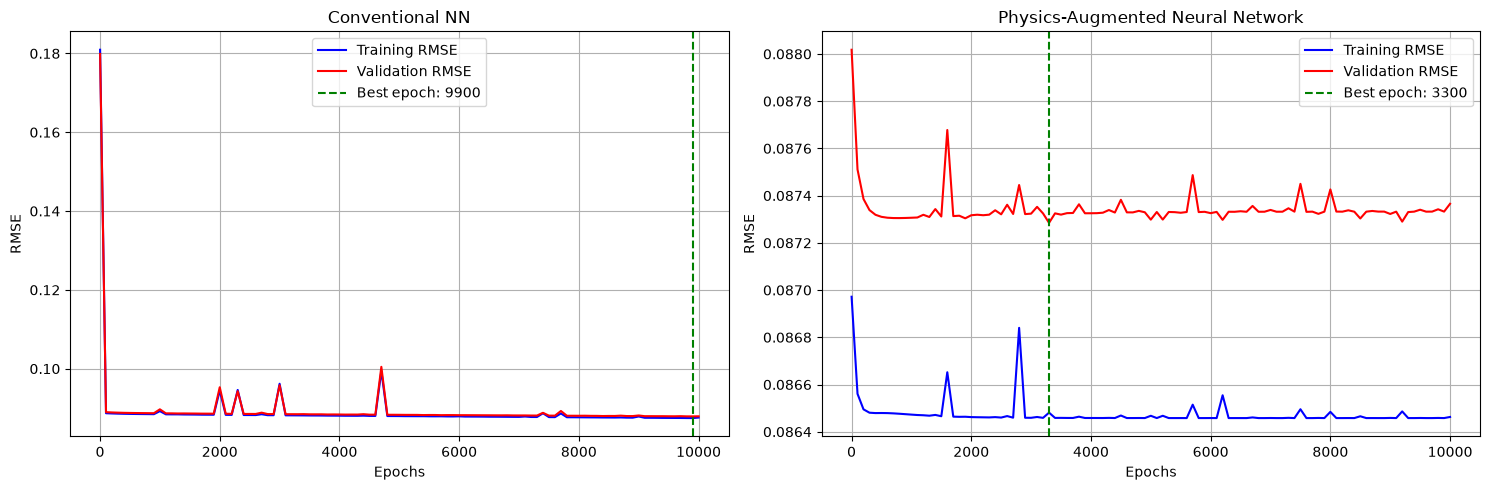

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Conventional NN
axes[0].plot(
    nn_epochs, nn_train,
    label="Training RMSE",
    color="blue"
)

axes[0].plot(
    nn_epochs, nn_val,
    label="Validation RMSE",
    color="red"
)

best_nn = np.argmin(nn_val)

axes[0].axvline(
    nn_epochs[best_nn],
    color="green",
    linestyle="--",
    label=f"Best epoch: {nn_epochs[best_nn]}"
)

axes[0].set_title("Conventional NN")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("RMSE")
axes[0].legend()
axes[0].grid(True)


# PANN
axes[1].plot(
    pann_epochs, pann_train,
    label="Training RMSE",
    color="blue"
)

axes[1].plot(
    pann_epochs, pann_val,
    label="Validation RMSE",
    color="red"
)

best_pann = np.argmin(pann_val)

axes[1].axvline(
    pann_epochs[best_pann],
    color="green",
    linestyle="--",
    label=f"Best epoch: {pann_epochs[best_pann]}"
)

axes[1].set_title("Physics-Augmented Neural Network")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("RMSE")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [27]:
print("Conventional NN")
print("Best epoch:", nn_epochs[best_nn])
print("Minimum validation RMSE:", nn_val[best_nn])

print("\nPANN")
print("Best epoch:", pann_epochs[best_pann])
print("Minimum validation RMSE:", pann_val[best_pann])

Conventional NN
Best epoch: 9900
Minimum validation RMSE: 0.08789535611867905

PANN
Best epoch: 3300
Minimum validation RMSE: 0.08728465437889099


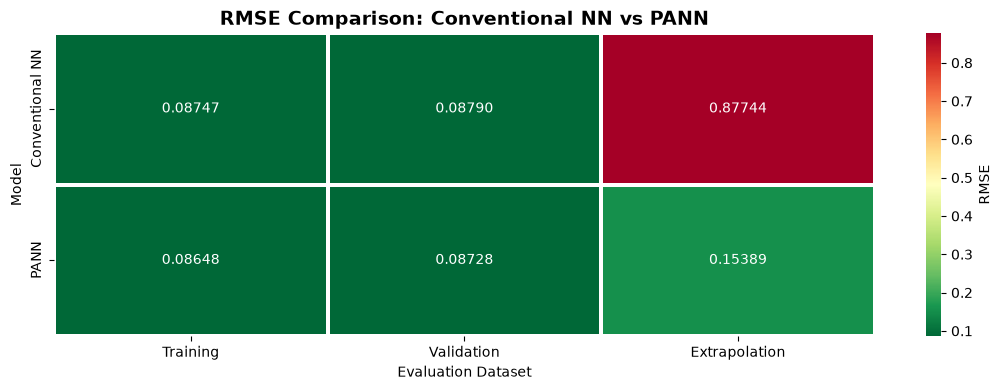

                 Training  Validation  Extrapolation
Conventional NN  0.087467    0.087895       0.877444
PANN             0.086481    0.087285       0.153890


In [31]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# 1. Best validation epochs
best_nn = np.argmin(nn_val)
best_pann = np.argmin(pann_val)

# 2. Training and validation RMSE
nn_train_rmse = nn_train[best_nn]
nn_val_rmse = nn_val[best_nn]

pann_train_rmse = pann_train[best_pann]
pann_val_rmse = pann_val[best_pann]

# 3. Extrapolation RMSE: lambda > 4
# Uses existing Gent stress and predictions
extrap_mask = lamda_plot[:, 0] > 4.0

def calculate_rmse(pred, true):
    return torch.sqrt(
        torch.mean((pred - true)**2)
    ).item()

nn_extrap_rmse = calculate_rmse(
    P_nn[extrap_mask],
    P_true[extrap_mask]
)

pann_extrap_rmse = calculate_rmse(
    P_pann[extrap_mask],
    P_true[extrap_mask]
)

# 4. Create comparison table
rmse_df = pd.DataFrame({
    "Training": [nn_train_rmse, pann_train_rmse],
    "Validation": [nn_val_rmse, pann_val_rmse],
    "Extrapolation": [nn_extrap_rmse, pann_extrap_rmse]
}, index=["Conventional NN", "PANN"])

# 5. Plot heatmap
plt.figure(figsize=(11, 4))

sns.heatmap(
    rmse_df,
    annot=True,
    fmt=".5f",
    cmap="RdYlGn_r",
    linewidths=1.5,
    linecolor="white",
    cbar_kws={"label": "RMSE"}
)

plt.title(
    "RMSE Comparison: Conventional NN vs PANN",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Evaluation Dataset")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

# 6. Print numerical comparison
print(rmse_df.round(6))


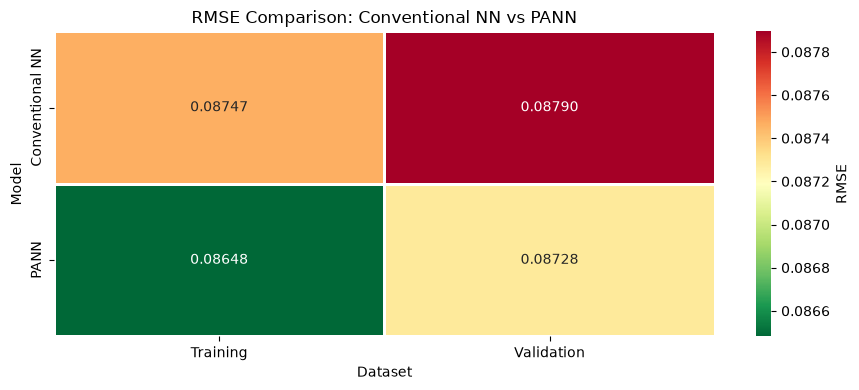

                 Training  Validation
Conventional NN  0.087467    0.087895
PANN             0.086481    0.087285


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Best validation epochs
best_nn = np.argmin(nn_val)
best_pann = np.argmin(pann_val)

# Create DataFrame using actual results
rmse_df = pd.DataFrame(
    {
        "Training": [
            nn_train[best_nn],
            pann_train[best_pann]
        ],
        "Validation": [
            nn_val[best_nn],
            pann_val[best_pann]
        ]
    },
    index=["Conventional NN", "PANN"]
)

plt.figure(figsize=(9, 4))

sns.heatmap(
    rmse_df,
    annot=True,
    fmt=".5f",
    cmap="RdYlGn_r",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "RMSE"}
)

plt.title("RMSE Comparison: Conventional NN vs PANN")
plt.xlabel("Dataset")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

print(rmse_df)

## Interpretation and limitations

- **Fixed original values:** `mu=0.8`, `jm=40`, `N=50000`, `λ∈[1,4]`, `eta_min=0.005`, `eta_max=0.03`, `m=32`, `Adam lr=0.01`, `epochs=10000`, original noise and Gent equations.
- **Controlled experimental changes:** 80/20 holdout validation split; a conventional direct-stress NN; a deterministic version of the original PANN energy network. The original hard-concrete gates and `rho=3.5` penalty are omitted from **both** models to avoid confounding architecture with sparsity.
- **Parameter counts are different:** the PANN has `1+3m=97` parameters; the one-hidden-layer conventional NN has `3m+1=97` parameters, so they match at `m=32`.
- The validation split is randomly interleaved in `[1,4]` and measures in-range prediction, not extrapolation.
- For research conclusions, repeat with several seeds and consider an untouched test set; a single run is not enough to establish a general advantage.
- The model is specialized to incompressible uniaxial deformation; testing other deformation modes would require a broader constitutive setup.